# PREDICCION DEL PM10 HASTA 2030

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. PM10 medio anual

In [3]:
anual = spark.sql ("""
    SELECT t.anio, 
    ROUND(AVG(a.concentracion),1) AS pm10_medio
    FROM gold.fact_aire a
    JOIN gold.dim_tiempo t 
        ON a.id_tiempo = t.id_tiempo
    JOIN gold.dim_contaminante c 
        ON a.id_contaminante = c.id_contaminante
        WHERE c.nombre = 'PM10'
        AND t.anio <= 2025
    GROUP by t.anio
    ORDER BY t.anio
    """).toPandas()

anual

ivysettings.xml file not found in HIVE_HOME or HIVE_CONF_DIR,/etc/hive/conf.dist/ivysettings.xml will be used


,anio,pm10_medio
0,2013,16.7
1,2014,15.6
2,2015,19.8
3,2016,17.4
4,2017,18.6
5,2018,19.5
6,2019,21.1
7,2020,14.5
8,2021,14.9
9,2022,19.8


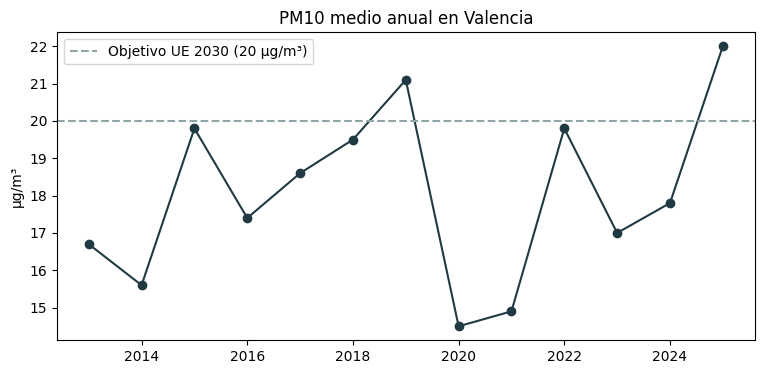

In [4]:
import io
from google.cloud import storage

plt.figure(figsize=(9, 4))
plt.plot(anual["anio"], anual["pm10_medio"], marker="o", color="#203A43")
plt.axhline(20, color="#8FA5A8", linestyle="--", label="Objetivo UE 2030 (20 µg/m³)")
plt.title("PM10 medio anual en Valencia")
plt.ylabel("µg/m³")
plt.legend()

# Guardar en el bucket
buffer = io.BytesIO()
plt.savefig(buffer, format="png", dpi=300, bbox_inches="tight")
bucket = storage.Client().bucket("tfm_unir1")
bucket.blob("processed/figuras/pm10_evolucion_anual.png").upload_from_string(
    buffer.getvalue(), content_type="image/png")

plt.show()

En este caso usaremos todos los años ya que si bien en 2020 baja, luego vuelve a subir. Entonces solo eliminamos los datos del 2020.

## 2. Modelo base: regresión lineal (excluimos 2020)

In [5]:
from sklearn.linear_model import LinearRegression

datos = anual[(anual["anio"] <= 2025) & (anual["anio"] != 2020)]

# Entrenamos el modelo: aprende cómo cmabia el PM10 según el año
modelo_lineal = LinearRegression()
modelo_lineal.fit(datos[["anio"]], datos["pm10_medio"])

print ("Cambio por año:", round(modelo_lineal.coef_[0],2), "µg/m³")

# Predecimos de 2026 a 2030
futuro = pd.DataFrame({"anio": range(2026, 2031)})
futuro["pm10_previsto"] = modelo_lineal.predict(futuro[["anio"]]).round(1)

futuro

/opt/conda/miniconda3/lib/python3.10/site-packages/scipy/__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.26.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Cambio por año: 0.17 µg/m³


,anio,pm10_previsto
0,2026,19.5
1,2027,19.7
2,2028,19.9
3,2029,20.0
4,2030,20.2


Este simple modelo indica que en 2030 el PM10 estaría en 20.2.
Para comprobar este modelo, vamos a evaluarlo con entrenamiento y test tomando los años del 2013-2024, sin 2020 como train y 2025 como test.
Son pocos datos, pero es una primera aproximación

### Evaluación del modelo base

In [6]:
from sklearn.metrics import mean_absolute_error

# Entrenamos solo con 2013-2024 y dejamos 2025 para probar

train_anual = anual[(anual["anio"]<=2024) & (anual["anio"]!=2020)]
test_anual  = anual[anual["anio"]==2025]

modelo_test = LinearRegression()
modelo_test.fit (train_anual[["anio"]], train_anual["pm10_medio"])

resultado = modelo_test.predict(test_anual[["anio"]])
prediccion_2025 = resultado[0]
real_2025 = test_anual["pm10_medio"].values[0]

print("Predicción 2025:", round(prediccion_2025, 1))
print("Valor real 2025:", real_2025)

error_lineal = mean_absolute_error([real_2025], [prediccion_2025])
print("MAE regresión lineal:", round(error_lineal, 2), "µg/m³")

Predicción 2025: 18.3
Valor real 2025: 22.0
MAE regresión lineal: 3.7 µg/m³


Nuestro modelo, entrenado con 2013-2024 (sin 2020) y prediciendo el 2025, se equivoca en 3.7 µg/m³ en su predicción. (3.7 sobre 22.2 es un error de alrededor de 17%.)
El error es mayor que en el NO2 porque el PM10 sube y baja mucho de un año a otro, y 2025 fue un año con valores altos.

La regresión lineal simple para 2030 predice un PM10 de 20.2 µg/m³ superior al objetivo de la UE que es 20 µg/m³ (1%). La diferencia con el objetivo es menor que el error del modelo, por lo que no se puede asegurar si en 2030 se cumplirá o no. A diferencia del NO2, el PM10 no baja con los años, y en 2025 ya estuvo por encima del objativo.

Como el modelo se evalúa con un solo año, se confirmarán las predicciones con un modelo mensual (SARIMA)

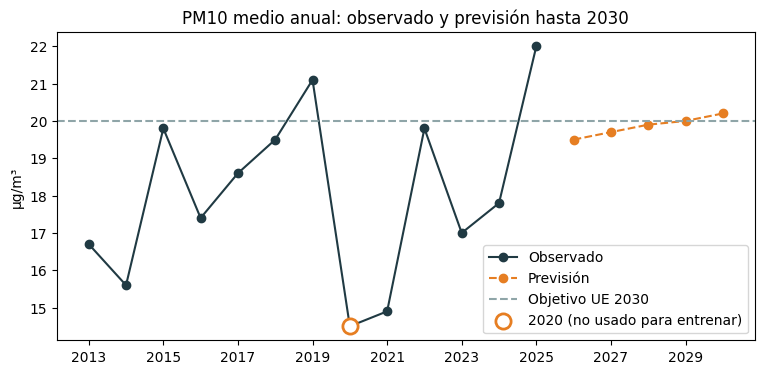

In [8]:
import io
from google.cloud import storage

plt.figure(figsize=(9, 4))
plt.plot(anual["anio"], anual["pm10_medio"], marker="o", color="#203A43", label="Observado")
plt.plot(futuro["anio"], futuro["pm10_previsto"], marker="o", linestyle="--", color="#E67E22", label="Previsión")
plt.axhline(20, color="#8FA5A8", linestyle="--", label="Objetivo UE 2030")
plt.title("PM10 medio anual: observado y previsión hasta 2030")

anio_2020 = anual[anual["anio"] == 2020]
plt.scatter(anio_2020["anio"], anio_2020["pm10_medio"], s=120, facecolors="white",
            edgecolors="#E67E22", linewidths=2, zorder=3, label="2020 (no usado para entrenar)")

plt.ylabel("µg/m³")
plt.legend()
plt.xticks(range(2013,2031,2))

# Guardar en el bucket
buffer = io.BytesIO()
plt.savefig(buffer, format="png", dpi=300, bbox_inches="tight")

bucket = storage.Client().bucket("tfm_unir1")
bucket.blob("processed/figuras/pm10_regresion_lineal.png").upload_from_string(
    buffer.getvalue(), content_type="image/png")

plt.show()

## 3. Modelo SARIMA mensual

En el modelo anual se excluyó 2020; en el mensual se mantuvo, porque el SARIMA necesita una serie continua, y con 13 años de datos su efecto es pequeño.

In [9]:
mensual = spark.sql ("""
    SELECT t.anio, t.mes, ROUND(AVG(a.concentracion),1) AS pm10_medio
    FROM gold.fact_aire a
    JOIN gold.dim_tiempo t 
        ON a.id_tiempo = t.id_tiempo
    JOIN gold.dim_contaminante c 
        ON a.id_contaminante = c.id_contaminante
        WHERE c.nombre = 'PM10'
        AND t.anio BETWEEN 2013 and 2025
    GROUP by t.anio, t.mes
    ORDER BY t.anio, t.mes
    """).toPandas()

mensual

,anio,mes,pm10_medio
0,2013,1,18.5
1,2013,2,18.2
2,2013,3,24.2
3,2013,4,20.6
4,2013,5,17.3
...,...,...,...
151,2025,8,29.0
152,2025,9,21.7
153,2025,10,19.2
154,2025,11,16.7


In [10]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Convertimos la tala en una serie con fecha completa
mensual ["fecha"] = pd.to_datetime(dict(year=mensual["anio"], month=mensual["mes"], day=1))
serie = mensual.set_index ("fecha")["pm10_medio"]
serie.index.freq = "MS"

# Entrenamiento: 2013-2024 (144 meses) / Test: 2025 (12 meses)
train_mensual = serie [:"2024-12-01"]
test_mensual = serie ["2025-01-01":]                            

### Usamos dos modelos SARIMAX distintos

No sabemos qué configuración del SARIMA funciona mejor con nuestros datos. Como vimos en los datos iniciales que hay un patrón estacional, usaremos dos que contemplan esa parte estacional (comparar cada mes con el mismo mes del año anterior) y se diferencias en como usan los meses anteriores:
    - SARIMA A: usa el valor del mes anterior.
    - SARIMA B: usa el cambio de un mes a otro y corrige su último error.

Para comparar los modelos usamos dos medidas de error sobre 2025:
- MAE (error absoluto medio): cuánto se equivoca en promedio cada mes
- MAPE (error porcentual medio): lo mismo, pero en porcentaje.
Cuanto más bajo el error, mejor predice el modelo.


In [11]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

# Referencia: predecir 2025 con los mismos meses de 2024
referencia = train_mensual ["2024-01-01":].values

#SARIMA A -- predice el valor usando el valor del mes pasado
modelo_a = SARIMAX(train_mensual, order=(1,0,0), seasonal_order=(0,1,1,12)).fit(disp=False)
pred_a = modelo_a.forecast(12) #predecimos1 año, 12 meses

#SARIMA B (airline) -- predice teniendo en cuenta los cambios mes a mes 
modelo_b = SARIMAX(train_mensual, order=(0,1,1), seasonal_order=(0,1,1,12)).fit(disp=False)
pred_b = modelo_b.forecast(12) #predecimos1 año, 12 meses

for nombre, prediccion in [("Referencia", referencia), ("SARIMA A", pred_a), ("SARIMA B", pred_b)]:
    mae  = mean_absolute_error(test_mensual, prediccion)
    mape = mean_absolute_percentage_error(test_mensual, prediccion) * 100
    print(nombre, "→ MAE:", round(mae, 2), "µg/m³ | MAPE:", round(mape, 1), "%")


Referencia → MAE: 6.92 µg/m³ | MAPE: 30.3 %
SARIMA A → MAE: 5.56 µg/m³ | MAPE: 23.2 %
SARIMA B → MAE: 4.95 µg/m³ | MAPE: 22.6 %


El SARIMA B tiene un MAE mas bajo. Ambos modelos mejoran la referencia.
Aun así, los errores son mayores que en el NO2 porque el PM10 varía mucho más de un mes a otro y es más dificil de predecir

In [12]:
# Reentrenamos con todos los datos (2013-2025) para predecir hasta 2030
final_a = SARIMAX(serie, order=(1,0,0), seasonal_order=(0,1,1,12)).fit(disp=False)
final_b = SARIMAX(serie, order=(0,1,1), seasonal_order=(0,1,1,12)).fit(disp=False)

# Predecimos de enero 2026 a diciembre 2030 (60 meses)
prev_a = final_a.forecast (60)
prev_b = final_b.forecast (60)

print("Promedio de los 12 meses en 2030:")
print("  SARIMA A:", round(prev_a ["2030"].mean(),1), "µg/m³")
print("  SARIMA B:", round(prev_b ["2030"].mean(),1),"µg/m³")

Promedio de los 12 meses en 2030:
  SARIMA A: 18.0 µg/m³
  SARIMA B: 16.5 µg/m³


El SARIMA A prevee 18,0 µg/m³ para 2030 y el SARIMA B, 16,5 µg/m³. La regresión lineal da un valor más alto (20,2), porque sigue la leve subida de todos los años.

A diferencia del NO2, los modelos no coinciden: sus previsiones van de 16,5 a 20,2 µg/m³, alrededor del objetivo de 20 µg/m³. Dos quedan por debajo y uno justo por encima.

In [13]:
# Usamos SARIMA B y calculamos el intervalo de confianza

# Previsión con intervalo de confianza del 95 %
prevision = final_b.get_forecast(60)
intervalo = prevision.conf_int(alpha=0.05)

# Promedio de los meses de 2030
print("Intervalo para 2030 (95 %):")
print("  Mínimo:", round(intervalo.loc["2030"].iloc[:, 0].mean(), 1), "µg/m³")
print("  Máximo:", round(intervalo.loc["2030"].iloc[:, 1].mean(), 1), "µg/m³")

Intervalo para 2030 (95 %):
  Mínimo: -27.4 µg/m³
  Máximo: 60.4 µg/m³


In [14]:
# No puede ser un intervalo negativo.
# Usaremos SARIMA A para ver qué intervalo genera

# Previsión con intervalo de confianza del 95 %
prevision = final_a.get_forecast(60)
intervalo = prevision.conf_int(alpha=0.05)

# Promedio de los meses de 2030
print("Intervalo para 2030 (95 %):")
print("  Mínimo:", round(intervalo.loc["2030"].iloc[:, 0].mean(), 1), "µg/m³")
print("  Máximo:", round(intervalo.loc["2030"].iloc[:, 1].mean(), 1), "µg/m³")

Intervalo para 2030 (95 %):
  Mínimo: 6.9 µg/m³
  Máximo: 29.2 µg/m³


El intervalo del SARIMA B para 2030 va de -27,4 a 60,4 µg/m³. No tiene sentido: el PM10 no puede ser negativo. El modelo B trabaja con los cambios de un mes a otro, y como el PM10 cambia mucho, a cinco años la incertidumbre se acumula hasta volverse inutilizable.

El SARIMA A da un intervalo razonable, de 6,9 a 29,2 µg/m³. Por eso, aunque el B predice mejor un año hacia adelante, para 2030 usamos el SARIMA A.

El intervalo del A incluye valores muy por encima de 20 µg/m³, así que no se puede asegurar que el PM10 cumpla el objetivo en 2030.

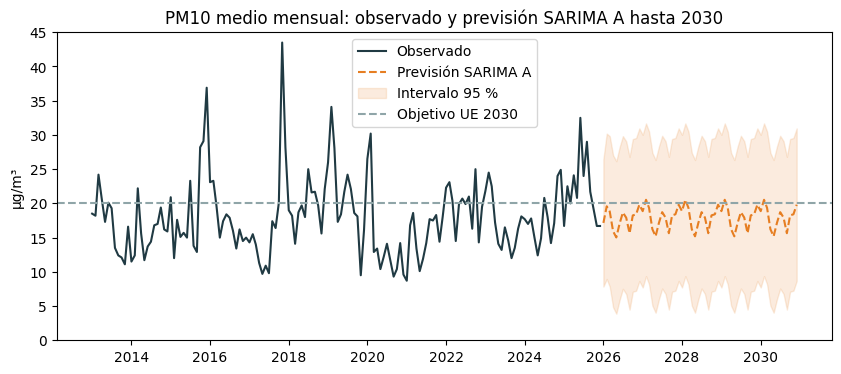

In [15]:
import io
from google.cloud import storage

plt.figure(figsize=(10, 4))
plt.plot(serie.index, serie, color="#203A43", label="Observado")
plt.plot(prev_a.index, prev_a, color="#E67E22", linestyle="--", label="Previsión SARIMA A")
plt.fill_between(intervalo.index, intervalo.iloc[:, 0], intervalo.iloc[:, 1],color="#E67E22", alpha=0.15, label="Intervalo 95 %")
plt.axhline(20, color="#8FA5A8", linestyle="--", label="Objetivo UE 2030")
plt.title("PM10 medio mensual: observado y previsión SARIMA A hasta 2030")
plt.ylabel("µg/m³")
plt.legend()
plt.ylim(0, 45)

# Guardar en el bucket
buffer = io.BytesIO()
plt.savefig(buffer, format="png", dpi=300, bbox_inches="tight")
bucket = storage.Client().bucket("tfm_unir1")
bucket.blob("processed/figuras/pm10_sarima_mensual.png").upload_from_string(
    buffer.getvalue(), content_type="image/png")

plt.show()

**Conclusión:** El PM10 no tiene un patrón estacional tan marcado como el NO2: presenta picos esporádicos y muy altos en distintas épocas del año, que el modelo no puede anticipar. Por eso la previsión es casi plana, entre 15 y 20 µg/m³.

La banda naranja mantiene casi el mismo ancho hasta 2030, pero es amplia: la previsión del PM10 es mucho menos segura que la del NO2.

Algunos meses superan los 20 µg/m³. No significa que no se cumpla el objetivo: el límite se refiere a la media anual, no a cada mes.

## 4. Guardar las predicciones en fact_prediccion

In [14]:
# Armamos el dataframe de las predicciones

from datetime import date

# Regresión lineal: un valor por año
tabla_lineal = pd.DataFrame({
    "modelo": "regresion_lineal",
    "indicador": "pm10",
    "horizonte": "2030",
    "granularidad": "anual",
    "fecha_ejecucion": date.today(),
    "fecha_prevista": pd.to_datetime(futuro["anio"].astype(str) + "-01-01").dt.date,
    "id_tiempo": None,
    "id_estacion": None,
    "valor_previsto": futuro["pm10_previsto"],
    "valor_bajo": None,
    "valor_alto": None,
})

# SARIMA A: un valor por mes, con intervalo
intervalo_a = final_a.get_forecast(60).conf_int(alpha=0.05)
tabla_sarima = pd.DataFrame({
    "modelo": "sarima_a",
    "indicador": "pm10",
    "horizonte": "2030",
    "granularidad": "mensual",
    "fecha_ejecucion": date.today(),
    "fecha_prevista": prev_a.index.date,
    "id_tiempo": None,
    "id_estacion": None,
    "valor_previsto": prev_a.round(1).values,
    "valor_bajo": intervalo_a.iloc[:, 0].round(1).values,
    "valor_alto": intervalo_a.iloc[:, 1].round(1).values,
})

# Juntamos las dos tablas
predicciones = pd.concat([tabla_lineal, tabla_sarima], ignore_index=True)
print(len(predicciones), "filas")
predicciones.head(7)

65 filas


/tmp/ipykernel_4376/244199100.py:37: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  predicciones = pd.concat([tabla_lineal, tabla_sarima], ignore_index=True)


,modelo,indicador,horizonte,granularidad,fecha_ejecucion,fecha_prevista,id_tiempo,id_estacion,valor_previsto,valor_bajo,valor_alto
0,regresion_lineal,pm10,2030,anual,2026-11-22,2026-01-01,None,None,19.5,NaN,NaN
1,regresion_lineal,pm10,2030,anual,2026-11-22,2027-01-01,None,None,19.7,NaN,NaN
2,regresion_lineal,pm10,2030,anual,2026-11-22,2028-01-01,None,None,19.9,NaN,NaN
3,regresion_lineal,pm10,2030,anual,2026-11-22,2029-01-01,None,None,20.0,NaN,NaN
4,regresion_lineal,pm10,2030,anual,2026-11-22,2030-01-01,None,None,20.2,NaN,NaN
5,sarima_a,pm10,2030,mensual,2026-11-22,2026-01-01,None,None,17.1,7.8,26.4
6,sarima_a,pm10,2030,mensual,2026-11-22,2026-02-01,None,None,19.6,9.0,30.2


In [16]:
# Guardamos en la GOLD

# Convertimos la tabla de pandas en una vista que spark.sql puede leer
# (sacamos id_tiempo e id_estacion porque están vacías; las ponemos como NULL en el SQL)
datos_pred = predicciones.drop(columns=["id_tiempo", "id_estacion"])

pd.DataFrame.iteritems = pd.DataFrame.items   # compatibilidad entre Spark y pandas
spark.createDataFrame(datos_pred).createOrReplaceTempView("predicciones")

spark.sql("""
    INSERT INTO gold.fact_prediccion
    SELECT modelo, indicador, horizonte, granularidad,
           CAST(fecha_ejecucion AS DATE),
           CAST(fecha_prevista AS DATE),
           CAST(NULL AS INT)    AS id_tiempo,
           CAST(NULL AS STRING) AS id_estacion,
           CAST(valor_previsto AS DOUBLE),
           CAST(valor_bajo AS DOUBLE),
           CAST(valor_alto AS DOUBLE),
           CAST (NULL as INT) AS id_distrito
    FROM predicciones
""")

spark.sql("SELECT modelo, COUNT(*) AS filas FROM gold.fact_prediccion GROUP BY modelo").show()

+-----------------+------+
|           modelo| filas|
+-----------------+------+
|gradient_boosting|100677|
|         sarima_b|    60|
| regresion_lineal|    10|
|         sarima_a|    60|
+-----------------+------+

